# Занятие 7. Классификация изображений на ручных признаках
## Полный классический ML-pipeline

**Часть 1** — демонстрация преподавателя.  
**Часть 2** — самостоятельные операции с уже знакомым ML.

## Часть 1. Демонстрация преподавателя

Фиксируем один split и сравниваем две вещи: **как представили изображение** и **какую классическую модель выбрали**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.base import clone

digits = load_digits()
images = digits.images.astype(np.float32)
y = digits.target

### 1. Те же feature extractors, что на прошлом занятии

In [2]:
def manual_features(img):
    h, w = img.shape
    return np.array([img.mean(), img[:h//2].mean(), img[h//2:].mean(), img[:, :w//2].mean(), img[:, w//2:].mean(), img[h//4:3*h//4, w//4:3*w//4].mean(), np.abs(img - np.fliplr(img)).mean(), np.abs(np.diff(img, axis=1)).mean(), np.abs(np.diff(img, axis=0)).mean()], dtype=np.float32)

def block_means(img):
    return img.reshape(4, 2, 4, 2).mean(axis=(1, 3)).ravel().astype(np.float32)

def orientation_features(img, bins=8):
    a = img.astype(np.float32); gx = np.zeros_like(a); gy = np.zeros_like(a)
    gx[:, 1:-1] = (a[:, 2:] - a[:, :-2]) / 2; gy[1:-1, :] = (a[2:, :] - a[:-2, :]) / 2
    mag = np.hypot(gx, gy); ang = (np.arctan2(gy, gx) + np.pi) % np.pi; feats = []
    for y0 in (0, 4):
        for x0 in (0, 4):
            hist, _ = np.histogram(ang[y0:y0+4, x0:x0+4], bins=bins, range=(0, np.pi), weights=mag[y0:y0+4, x0:x0+4])
            feats.extend(hist / (np.linalg.norm(hist) + 1e-8))
    return np.asarray(feats, dtype=np.float32)

### 2. Один split для всех экспериментов
Разделяем **индексы**, чтобы затем применить один и тот же split к любой матрице признаков.

In [3]:
train_idx, test_idx = train_test_split(
    np.arange(len(images)), test_size=0.25, random_state=42, stratify=y
)
print(len(train_idx), len(test_idx))

1347 450


### 3. Четыре representation одного датасета

In [4]:
X_raw = images.reshape(len(images), -1)
X_manual = np.stack([manual_features(img) for img in images])
X_blocks = np.stack([block_means(img) for img in images])
X_orient = np.stack([orientation_features(img) for img in images])
representations = {'pixels': X_raw, 'manual': X_manual, 'blocks': X_blocks, 'gradients': X_orient}
for name, X in representations.items(): print(name, X.shape)

pixels (1797, 64)
manual (1797, 9)
blocks (1797, 16)
gradients (1797, 32)


### 4. Несколько знакомых моделей
Для kNN, logistic regression и SVM используем scaler внутри Pipeline.

In [5]:
models = {
    'kNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2500)),
    'SVM': make_pipeline(StandardScaler(), SVC(C=3)),
    'RandomForest': RandomForestClassifier(n_estimators=180, random_state=42, n_jobs=-1),
}

### 5. Таблица representation × model
Это главный эксперимент занятия.

In [6]:
results = {}
for rep_name, X in representations.items():
    results[rep_name] = {}
    for model_name, model in models.items():
        m = clone(model)
        m.fit(X[train_idx], y[train_idx])
        pred = m.predict(X[test_idx])
        results[rep_name][model_name] = accuracy_score(y[test_idx], pred)

print('representation'.ljust(12), *[name.rjust(13) for name in models])
for rep_name in representations:
    print(rep_name.ljust(12), *[f'{results[rep_name][m]:13.3f}' for m in models])

representation           kNN        LogReg           SVM  RandomForest
pixels               0.964         0.978         0.980         0.967
manual               0.822         0.780         0.822         0.822
blocks               0.931         0.904         0.969         0.940
gradients            0.871         0.887         0.924         0.902


### 6. Одна accuracy не объясняет ошибки
Посмотрим confusion matrix для компактных `blocks` + SVM.

accuracy: 0.9688888888888889


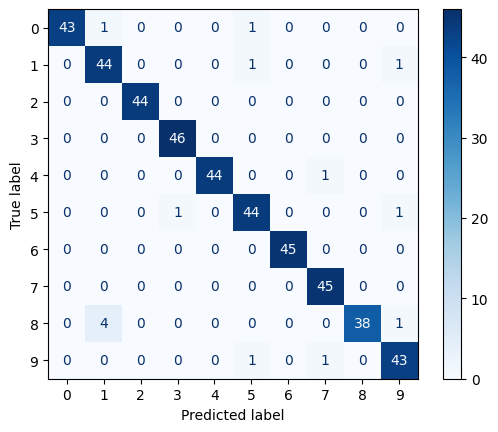

In [7]:
model_blocks = clone(models['SVM'])
model_blocks.fit(X_blocks[train_idx], y[train_idx])
pred_blocks = model_blocks.predict(X_blocks[test_idx])
print('accuracy:', accuracy_score(y[test_idx], pred_blocks))
ConfusionMatrixDisplay.from_predictions(y[test_idx], pred_blocks, cmap='Blues')
plt.show()

### 7. Смотрим конкретные ошибки
Метрика возвращает нас к изображениям.

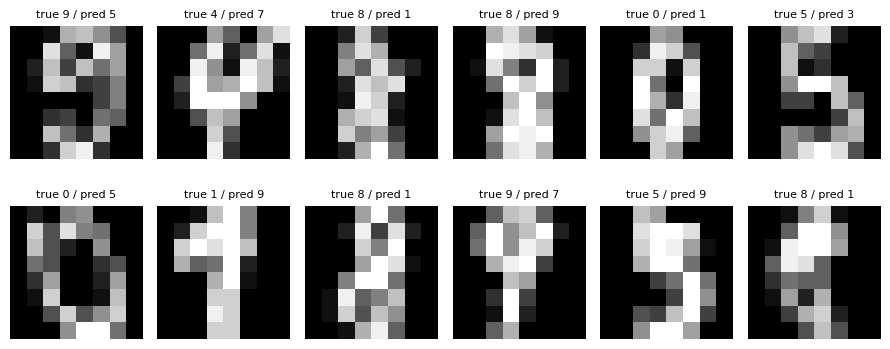

In [8]:
wrong = np.flatnonzero(pred_blocks != y[test_idx])
fig, axes = plt.subplots(2, 6, figsize=(9, 4))
for ax, pos in zip(axes.ravel(), wrong[:12]):
    idx = test_idx[pos]
    ax.imshow(images[idx], cmap='gray', vmin=0, vmax=16)
    ax.set_title(f'true {y[idx]} / pred {pred_blocks[pos]}', fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()

---
## Часть 2. Самостоятельные мини-задачи

Используем уже определённые `images`, `y`, feature extractors и `train_idx/test_idx`.

### Задание 1. Сырые пиксели
Создайте `X_raw_s` формы `(N, 64)`.

In [9]:
# YOUR CODE HERE (1 строка)
# X_raw_s = ...

### Задание 2. Локальные средние
Создайте `X_blocks_s` для всех изображений.

In [10]:
# YOUR CODE HERE (1 строка)
# X_blocks_s = ...

### Задание 3. Ручные статистики
Создайте `X_manual_s`.

In [11]:
# YOUR CODE HERE (1 строка)
# X_manual_s = ...

### Задание 4. Создайте SVM pipeline
`StandardScaler()` + `SVC(C=3)`.

In [12]:
# YOUR CODE HERE (1 строка)
# model_s = ...

### Задание 5. Обучите на block-признаках

In [13]:
# YOUR CODE HERE (1 строка)
# model_s.fit(...)

### Задание 6. Получите предсказания
Создайте `pred_s` для test.

In [14]:
# YOUR CODE HERE (1 строка)
# pred_s = ...

### Задание 7. Посчитайте accuracy
Создайте `score_s`.

In [15]:
# YOUR CODE HERE (1 строка)
# score_s = ...

### Задание 8. Найдите ошибки
`wrong_s` — позиции неправильных ответов внутри test.

In [16]:
# YOUR CODE HERE (1 строка)
# wrong_s = ...

### Задание 9. Сравните с сырыми пикселями
Создайте и обучите такой же SVM pipeline на `X_raw_s`, результат запишите в `score_raw_s`.

In [17]:
# YOUR CODE HERE (2–3 строки)
# model_raw_s = ...
# model_raw_s.fit(...)
# score_raw_s = ...

### Финальный вопрос модуля
В сегодняшнем pipeline модель сама выбирает правило классификации, но кто выбрал признаки? Какую часть этой работы мы хотим передать нейросети в следующем модуле?